# IMDb Movie Review Sentiment Analysis

## Project Overview
This mini-project uses Natural Language Processing (NLP) and Machine Learning to classify IMDb movie reviews as positive or negative.

## Project Workflow
1. Load the IMDb review dataset.
2. Preprocess and clean the review text.
3. Explore the dataset using descriptive statistics and visualizations.
4. Train a sentiment classification model using TF-IDF and Linear Support Vector Classification (LinearSVC).
5. Evaluate the model using classification metrics and a confusion matrix.
6. Save the trained model and test it on new reviews.
7. Use the saved model in a Streamlit application.

## 1. Dataset Loading

The IMDb dataset contains movie reviews and their corresponding sentiment labels.

- **`review`**: The text of the movie review.
- **`sentiment`**: The sentiment label, either positive or negative.

The dataset is loaded into a Pandas DataFrame for further processing and analysis.

In [1]:
import pandas as pd

df = pd.read_csv("IMDB-Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 2. Text Preprocessing and Feature Extraction

This section prepares the review text for analysis and extracts basic text features.

The `preprocess_kgptalkie` package is used to calculate word counts, character counts, average word length, and stopword counts. HTML tags are removed, text is converted to lowercase, and stopwords are removed to create an additional processed-review column.

In [2]:
import preprocess_kgptalkie as ps

print("Preprocessing package loaded successfully!")

Preprocessing package loaded successfully!


In [6]:
print([name for name in dir(ps) if any(k in name.lower() for k in ['word', 'char', 'stop'])])

['Word', 'avg_word_len', 'char_count', 'pluralize_words', 'remove_accented_chars', 'remove_common_words', 'remove_rare_words', 'remove_repeated_chars', 'remove_special_chars', 'remove_stop_words', 'singularize_words', 'stop_words_count', 'stopwords', 'word_count']


In [7]:
df['word_counts'] = df['review'].apply(ps.word_count)
df['char_counts'] = df['review'].apply(ps.char_count)
df['avg_wordlength'] = df['review'].apply(ps.avg_word_len)
df['stopwords_counts'] = df['review'].apply(ps.stop_words_count)

df['review'] = df['review'].apply(ps.remove_html_tags)
df['review'] = df['review'].str.lower()

In [8]:
df.head()

,review,sentiment,word_counts,char_counts,stopwords_counts,avg_wordlength
0,one of the other reviewers has mentioned that ...,positive,301,1425,147,4.734219
1,a wonderful little production. the filming tec...,positive,156,807,78,5.173077
2,i thought this was a wonderful way to spend ti...,positive,162,741,87,4.574074
3,basically there's a family where a little boy ...,negative,132,581,67,4.401515
4,"petter mattei's ""love in the time of money"" is...",positive,222,1048,112,4.720721


In [9]:
df['review_without_stopwords'] = df['review'].apply(lambda x: ps.remove_stop_words(x))

In [10]:
df.head()

,review,sentiment,word_counts,char_counts,stopwords_counts,avg_wordlength,review_without_stopwords
0,one of the other reviewers has mentioned that ...,positive,301,1425,147,4.734219,reviewers mentioned watching 1 oz episode you'...
1,a wonderful little production. the filming tec...,positive,156,807,78,5.173077,wonderful little production. filming technique...
2,i thought this was a wonderful way to spend ti...,positive,162,741,87,4.574074,thought wonderful way spend time hot summer we...
3,basically there's a family where a little boy ...,negative,132,581,67,4.401515,basically there's family little boy (jake) thi...
4,"petter mattei's ""love in the time of money"" is...",positive,222,1048,112,4.720721,"petter mattei's ""love time money"" visually stu..."


In [11]:
print(df.columns.tolist())

['review', 'sentiment', 'word_counts', 'char_counts', 'stopwords_counts', 'avg_wordlength', 'review_without_stopwords']


In [12]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

## 3. Data Quality Checks and Cleaning

This section checks the dataset for missing values and duplicate movie reviews.

- **Missing values:** `isnull().sum()` identifies missing values in each column.
- **Duplicate reviews:** `duplicated()` identifies repeated reviews.
- **Duplicate inspection:** A sample of duplicate reviews is displayed for verification.
- **Duplicate removal:** Repeated reviews are removed while retaining the first occurrence, and the DataFrame index is reset.

These checks help improve the consistency of the dataset before exploratory data analysis and model training.

In [13]:
df.isnull().sum()

review                      0
sentiment                   0
word_counts                 0
char_counts                 0
stopwords_counts            0
avg_wordlength              0
review_without_stopwords    0
dtype: int64

In [14]:
df.duplicated(subset=['review']).sum()

np.int64(419)

In [15]:
df[df.duplicated(subset=['review'], keep=False)].sort_values('review').head(10)

,review,sentiment,word_counts,char_counts,stopwords_counts,avg_wordlength,review_without_stopwords
47467,"""go fish"" garnered rose troche rightly or wron...",negative,123,573,68,4.658537,"""go fish"" garnered rose troche rightly wrongly..."
34058,"""go fish"" garnered rose troche rightly or wron...",negative,123,573,68,4.658537,"""go fish"" garnered rose troche rightly wrongly..."
29956,"""three"" is a seriously dumb shipwreck movie. m...",negative,361,1843,161,5.105263,"""three"" seriously dumb shipwreck movie. masque..."
31488,"""three"" is a seriously dumb shipwreck movie. m...",negative,361,1843,161,5.105263,"""three"" seriously dumb shipwreck movie. masque..."
47527,"""witchery"" might just be the most incoherent a...",negative,285,1511,125,5.301754,"""witchery"" incoherent lamentably scripted horr..."
2976,"""witchery"" might just be the most incoherent a...",negative,285,1511,125,5.301754,"""witchery"" incoherent lamentably scripted horr..."
32260,'dead letter office' is a low-budget film abou...,negative,163,815,81,5.000000,'dead letter office' low-budget film couple em...
7949,'dead letter office' is a low-budget film abou...,negative,163,815,81,5.000000,'dead letter office' low-budget film couple em...
22449,(spoilers)oh sure it's based on moby dick. tot...,negative,163,788,69,4.834356,(spoilers)oh sure it's based moby dick. totall...
18022,(spoilers)oh sure it's based on moby dick. tot...,negative,163,788,69,4.834356,(spoilers)oh sure it's based moby dick. totall...


In [16]:
df = df.drop_duplicates(subset=['review'], keep='first').reset_index(drop=True)
print(df.shape)

(49581, 7)


In [17]:
df['sentiment'].value_counts()


sentiment
positive    24884
negative    24697
Name: count, dtype: int64

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset's structure, text characteristics, and sentiment distribution before building the machine learning model.

### 4.1 Descriptive Statistics

The `describe()` method summarizes the numerical text features, including word counts, character counts, average word length, and stopword counts. It provides statistics such as the mean, standard deviation, minimum, maximum, and quartiles.

In [18]:
df[['word_counts', 'char_counts', 'avg_wordlength', 'stopwords_counts']].describe()

,word_counts,char_counts,avg_wordlength,stopwords_counts
count,49581.000000,49581.000000,49581.000000,49581.000000
mean,227.308102,1059.994796,4.635949,115.436034
std,168.476032,804.343054,0.345476,85.420999
min,4.000000,27.000000,1.239865,0.000000
25%,125.000000,565.000000,4.409357,63.000000
50%,171.000000,785.000000,4.620155,88.000000
75%,276.000000,1286.000000,4.844560,139.000000
max,2450.000000,11135.000000,13.531915,1174.000000


In [20]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 4.2 Distribution of Review Lengths

A histogram displays how review word counts are distributed across the dataset. It helps identify common review lengths and unusually long reviews.

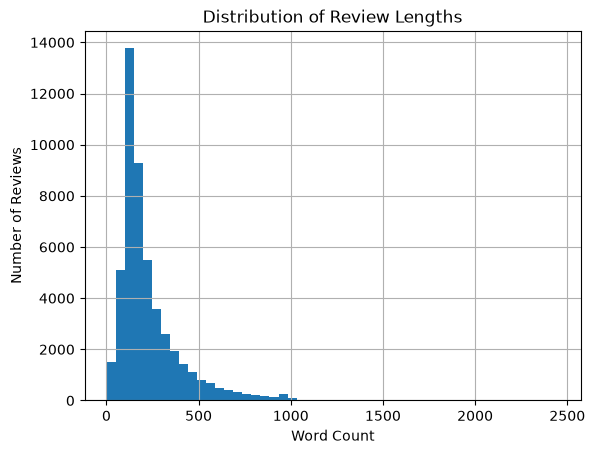

In [21]:
import matplotlib.pyplot as plt

df['word_counts'].hist(bins=50)
plt.xlabel('Word Count')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Review Lengths')
plt.show()

### 4.3 Review Length by Sentiment

This section compares word-count statistics for positive and negative reviews to examine differences in their lengths.

In [22]:
df.groupby('sentiment')['word_counts'].describe()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24697.0,225.438150,162.005921,4.0,126.0,171.0,273.0,1474.0
positive,24884.0,229.164001,174.644166,10.0,123.0,170.0,278.0,2450.0


### 4.4 Sentiment Distribution

A bar chart compares the number of positive and negative reviews in the dataset. This helps determine whether the sentiment classes are balanced.

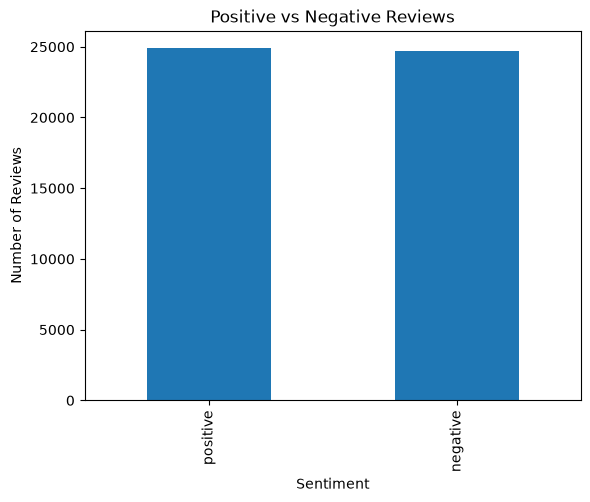

In [23]:
df['sentiment'].value_counts().plot(kind='bar')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.title('Positive vs Negative Reviews')
plt.show()

In [24]:
df['review_without_stopwords'].head()

0    reviewers mentioned watching 1 oz episode you'...
1    wonderful little production. filming technique...
2    thought wonderful way spend time hot summer we...
3    basically there's family little boy (jake) thi...
4    petter mattei's "love time money" visually stu...
Name: review_without_stopwords, dtype: str

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49581 entries, 0 to 49580
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   review                    49581 non-null  str    
 1   sentiment                 49581 non-null  str    
 2   word_counts               49581 non-null  int64  
 3   char_counts               49581 non-null  int64  
 4   stopwords_counts          49581 non-null  int64  
 5   avg_wordlength            49581 non-null  float64
 6   review_without_stopwords  49581 non-null  str    
dtypes: float64(1), int64(3), str(3)
memory usage: 2.6 MB


In [26]:
df['sentiment'].value_counts()

sentiment
positive    24884
negative    24697
Name: count, dtype: int64

In [27]:
df.groupby('sentiment')['avg_wordlength'].mean()

sentiment
negative    4.617790
positive    4.653971
Name: avg_wordlength, dtype: float64

In [29]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import seaborn as sns
print("Seaborn installed successfully!")

Seaborn installed successfully!


### 4.5 Distribution of Text Features

These visualizations compare positive and negative reviews across four features:

- Word counts
- Character counts
- Average word length
- Stopword counts

The plots help explore whether these text characteristics differ between the two sentiment classes.

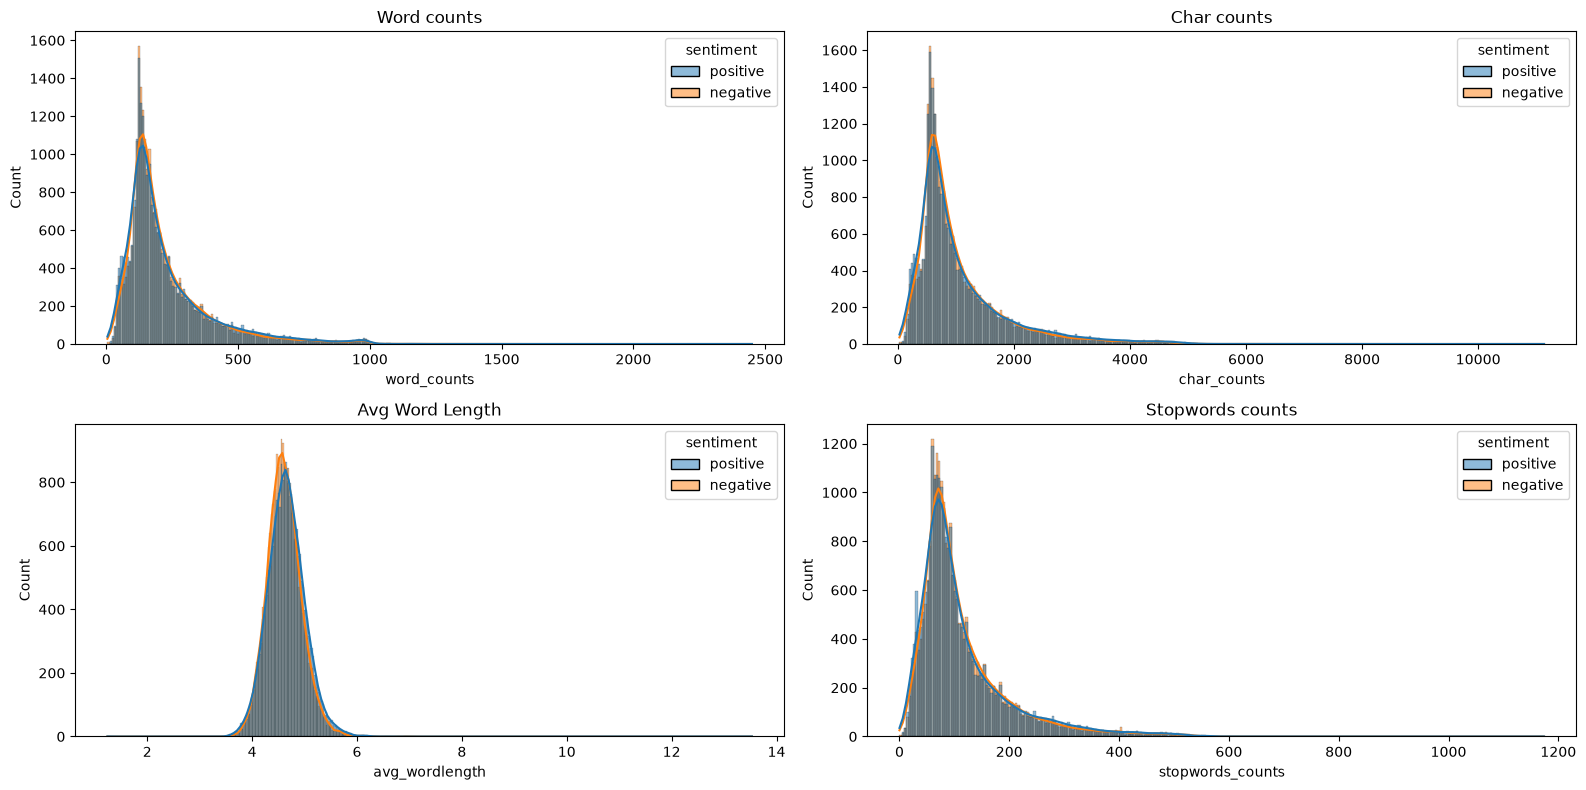

In [31]:
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
sns.histplot(data=df, x='word_counts', hue='sentiment', kde=True)
plt.title('Word counts')

plt.subplot(2, 2, 2)
sns.histplot(data=df, x='char_counts', hue='sentiment', kde=True)
plt.title('Char counts')

plt.subplot(2, 2, 3)
sns.histplot(data=df, x='avg_wordlength', hue='sentiment', kde=True)
plt.title('Avg Word Length')

plt.subplot(2, 2, 4)
sns.histplot(data=df, x='stopwords_counts', hue='sentiment', kde=True)
plt.title('Stopwords counts')

plt.tight_layout()
plt.show()

In [33]:
'clf' in globals(), 'X_train' in globals(), 'y_train' in globals()

(False, False, False)

In [36]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 2.1/36.7 MB 10.7 MB/s eta 0:00:04
   ----- ---------------------------------- 4.7/36.7 MB 11.0 MB/s eta 0:00:03
   ------- -------------------------------- 7.1/36.7 MB 11.2 MB/s eta 0:00:03
   ---------- ----------------------------- 9.7/36.7 MB 11.2 MB/s eta 0:00:03
   ------------- -------------------------- 12.1/36.7 MB 11.3 MB/s eta 0:00:03
   --------------- ------------------------ 14.4/36.7 MB 11.1 MB/s eta 0:00:03
   ------------------ --------------------- 16.5/36.7 M


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 5. Model Building

This section trains a machine learning model to classify IMDb movie reviews as positive or negative.

### 5.1 Train-Test Split

The dataset is divided into training and testing sets. The training set is used to train the model, while the testing set evaluates its performance on unseen reviews.

An 80:20 split is used, with stratification to preserve the approximate sentiment distribution in both sets.

### 5.2 TF-IDF Vectorization and LinearSVC

- **TF-IDF Vectorizer:** Converts review text into numerical features based on word importance.
- **LinearSVC:** A Support Vector Machine classifier that learns to distinguish positive reviews from negative reviews.
- **Pipeline:** Combines text vectorization and classification into one workflow.

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    df['review'],
    df['sentiment'],
    test_size=0.2,
    random_state=0,
    stratify=df['sentiment']
)

X_train.shape, X_test.shape

((39664,), (9917,))

In [39]:
clf = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LinearSVC())
])

In [40]:
clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['negative','positive']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


## 6. Model Evaluation

The trained model is evaluated using the testing dataset to measure how effectively it classifies unseen movie reviews.

### 6.1 Classification Report

The classification report provides the following evaluation metrics:

- **Precision:** The proportion of predicted positive cases for a class that are correct.
- **Recall:** The proportion of actual cases of a class that the model correctly identifies.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** The number of actual test samples belonging to each class.

These metrics help assess the model's ability to distinguish between positive and negative reviews.

In [41]:
y_pred = clf.predict(X_test)

In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.91      0.90      0.90      4940
    positive       0.90      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [46]:
%pip install mlxtend

  Using cached mlxtend-0.25.0-py3-none-any.whl.metadata (7.4 kB)
Using cached mlxtend-0.25.0-py3-none-any.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 6.2 Confusion Matrix

The confusion matrix compares the model's predicted sentiment labels with the actual sentiment labels.

It helps identify correctly classified reviews and errors made when predicting positive or negative sentiment.

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

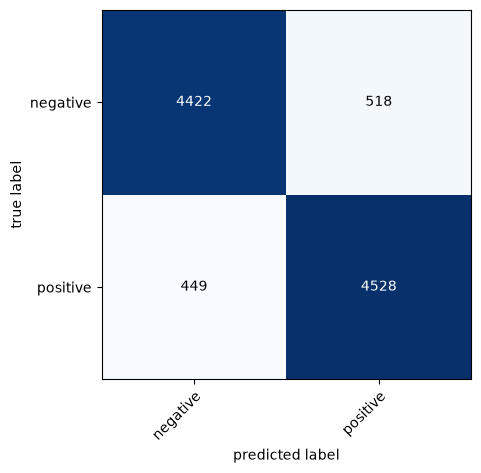

In [47]:
from mlxtend.plotting import plot_confusion_matrix

cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(cm, class_names=clf.classes_)

## 7. Saving the Trained Model

The trained machine learning pipeline is saved as `sentiment_analysis.pkl` using Python's `pickle` module.

Saving the pipeline allows the trained model and its TF-IDF vectorizer to be loaded later without retraining, including when running the Streamlit application.

In [49]:
import pickle

with open('sentiment_analysis.pkl', 'wb') as f:
    pickle.dump(clf, f)

In [50]:
import os
print(os.path.abspath('sentiment_analysis.pkl'))

C:\Users\ram18\Downloads\sentiment_analysis.pkl


## 8. Testing Sentiment Predictions

The trained model is tested on new text inputs to check whether it can predict the sentiment of individual movie reviews.

### 8.1 Positive Review Prediction

This test checks whether the model correctly identifies a positive review.

In [54]:
clf.predict(['Wow, this is an amazing lesson'])

array(['positive'], dtype=object)

### 8.2 Negative Review Prediction

This test checks whether the model correctly identifies a negative review.

In [55]:
clf.predict(['Wow, this sucks'])

array(['negative'], dtype=object)

## 9. Conclusion

In this mini-project, an IMDb movie review sentiment analysis system was developed using Natural Language Processing (NLP) and Machine Learning.

The dataset was cleaned and explored using descriptive statistics and visualizations. A machine learning pipeline combining TF-IDF vectorization and LinearSVC was trained to classify movie reviews as positive or negative.

The model was evaluated using a classification report and confusion matrix, achieving approximately 90% accuracy on the test dataset. The trained pipeline was saved using Pickle and integrated into a Streamlit application.

The application was tested using positive and negative text inputs and produced the expected predictions for the examples tested.

This project demonstrates how text preprocessing, exploratory data analysis, machine learning, model evaluation, and a simple web interface can be combined to build a sentiment classification application.